<a href="https://colab.research.google.com/github/bensilas94/Case-Exercise-/blob/main/BEN_SILAS_OGBARA_Case_Exercise_1_PT_Design_Envelope.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 1. Implement the pressure_temperature_envelope() function from Section 2.2.2(slide 170) with full documentation and error handling

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def pressure_temperature_envelope(
    p_max: float = 4467.0,
    p_min: float = 500.0,
    t_min_seabed: float = 4.0,
    t_max_reservoir: float = 82.0,
    hydrate_offset: float = 5.0,
    wat_c: float = 35.0,
    n_points: int = 100,
) -> dict:
    """Build a simplified pressure–temperature (P–T) envelope for a subsea system."""
    numeric_parameters = {
        "p_max": p_max,
        "p_min": p_min,
        "t_min_seabed": t_min_seabed,
        "t_max_reservoir": t_max_reservoir,
        "hydrate_offset": hydrate_offset,
        "wat_c": wat_c,
    }

    for name, value in numeric_parameters.items():
        if isinstance(value, (bool, np.bool_)) or not isinstance(
            value, (int, float, np.integer, np.floating)
        ):
            raise TypeError(f"{name} must be a real numeric value.")
        if not np.isfinite(value):
            raise ValueError(f"{name} must be finite.")

    if isinstance(n_points, (bool, np.bool_)) or not isinstance(n_points, (int, np.integer)):
        raise TypeError("n_points must be an integer.")
    if n_points < 2:
        raise ValueError("n_points must be at least 2.")
    if p_min <= 0:
        raise ValueError("p_min must be greater than zero.")
    if p_max <= p_min:
        raise ValueError("p_max must be greater than p_min.")
    if t_max_reservoir <= t_min_seabed:
        raise ValueError("t_max_reservoir must be greater than t_min_seabed.")
    if hydrate_offset < 0:
        raise ValueError("hydrate_offset cannot be negative.")
    if wat_c >= t_max_reservoir:
        raise ValueError("wat_c must be below t_max_reservoir.")

    pressures = np.linspace(float(p_min), float(p_max), int(n_points))
    t_hydrate = float(t_min_seabed) + 18.0 * np.log10(pressures / 200.0)
    t_safe_hydrate = t_hydrate + float(hydrate_offset)
    t_safe_min = np.maximum(t_safe_hydrate, float(wat_c))

    return {
        "pressures_psi": pressures,
        "t_hydrate_c": t_hydrate,
        "t_safe_hydrate_c": t_safe_hydrate,
        "t_safe_min_c": t_safe_min,
        "wat_c": float(wat_c),
        "p_min_psi": float(p_min),
        "p_max_psi": float(p_max),
        "t_min_seabed_c": float(t_min_seabed),
        "t_max_c": float(t_max_reservoir),
        "n_points": int(n_points),
    }

envelope = pressure_temperature_envelope()
print(f"Pressure range: {envelope['p_min_psi']:.0f}–{envelope['p_max_psi']:.0f} psi")
print(f"Temperature ceiling: {envelope['t_max_c']:.1f} °C")
print(f"Hydrate temperature at MAOP: {envelope['t_hydrate_c'][-1]:.2f} °C")
print(f"Hydrate-safe temperature at MAOP (+5°C): {envelope['t_safe_hydrate_c'][-1]:.2f} °C")
print(f"Lower safe-temperature boundary at MAOP: {envelope['t_safe_min_c'][-1]:.2f} °C")

Pressure range: 500–4467 psi
Temperature ceiling: 82.0 °C
Hydrate temperature at MAOP: 28.28 °C
Hydrate-safe temperature at MAOP (+5°C): 33.28 °C
Lower safe-temperature boundary at MAOP: 35.00 °C


Question 2. Create a 2D P-T envelope plot showing the safe operating region, hydrate curve, WAT line, and MAOP boundary. Plot the six jumper operating points from Table 2.9 on the envelope.


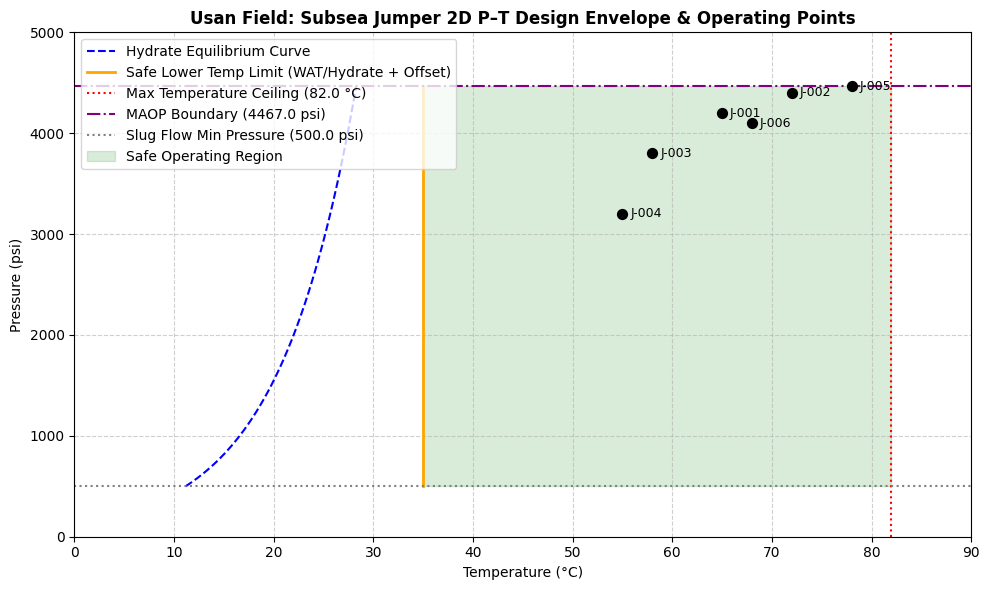

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def pressure_temperature_envelope(
    p_max: float = 4467.0,
    p_min: float = 500.0,
    t_min_seabed: float = 4.0,
    t_max_reservoir: float = 82.0,
    hydrate_offset: float = 5.0,
    wat_c: float = 35.0,
    n_points: int = 100,
) -> dict:
    """Build a simplified pressure–temperature (P–T) envelope for a subsea system."""
    pressures = np.linspace(float(p_min), float(p_max), int(n_points))
    t_hydrate = float(t_min_seabed) + 18.0 * np.log10(pressures / 200.0)
    t_safe_hydrate = t_hydrate + float(hydrate_offset)
    t_safe_min = np.maximum(t_safe_hydrate, float(wat_c))

    return {
        "pressures_psi": pressures,
        "t_hydrate_c": t_hydrate,
        "t_safe_hydrate_c": t_safe_hydrate,
        "t_safe_min_c": t_safe_min,
        "wat_c": float(wat_c),
        "p_min_psi": float(p_min),
        "p_max_psi": float(p_max),
        "t_min_seabed_c": float(t_min_seabed),
        "t_max_c": float(t_max_reservoir),
    }

# 1. Generate envelope boundaries
env = pressure_temperature_envelope()

# 2. Table 2.9: Jumper Operating Points (J-001 to J-006)
jumpers = {
    "J-001": {"pressure": 4200, "temp": 65},
    "J-002": {"pressure": 4400, "temp": 72},
    "J-003": {"pressure": 3800, "temp": 58},
    "J-004": {"pressure": 3200, "temp": 55},
    "J-005": {"pressure": 4467, "temp": 78},
    "J-006": {"pressure": 4100, "temp": 68},
}

# 3. Create the 2D P-T Envelope Plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot boundary curves
ax.plot(env["t_hydrate_c"], env["pressures_psi"], label="Hydrate Equilibrium Curve", color="blue", linestyle="--")
ax.plot(env["t_safe_min_c"], env["pressures_psi"], label="Safe Lower Temp Limit (WAT/Hydrate + Offset)", color="orange", linewidth=2)
ax.axvline(x=env["t_max_c"], color="red", linestyle=":", label=f"Max Temperature Ceiling ({env['t_max_c']} °C)")
ax.axhline(y=env["p_max_psi"], color="purple", linestyle="-.", label=f"MAOP Boundary ({env['p_max_psi']} psi)")
ax.axhline(y=env["p_min_psi"], color="gray", linestyle=":", label=f"Slug Flow Min Pressure ({env['p_min_psi']} psi)")

# Shade the safe operating region
ax.fill_betweenx(
    env["pressures_psi"],
    env["t_safe_min_c"],
    env["t_max_c"],
    color="green",
    alpha=0.15,
    label="Safe Operating Region"
)

# Plot Table 2.9 Jumper Operating Points
for j_id, data in jumpers.items():
    ax.scatter(data["temp"], data["pressure"], color="black", s=50, zorder=5)
    ax.text(data["temp"] + 0.8, data["pressure"], j_id, fontsize=9, verticalalignment="center")

# Formatting and Labels
ax.set_title("Usan Field: Subsea Jumper 2D P–T Design Envelope & Operating Points", fontsize=12, fontweight="bold")
ax.set_xlabel("Temperature (°C)", fontsize=10)
ax.set_ylabel("Pressure (psi)", fontsize=10)
ax.set_xlim(0, 90)
ax.set_ylim(0, 5000)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

  Question 3. Extend to a 3-parameter envelope (P-T-flow rate) and create a 3D scatter plot showing operating points coloured by envelope status.


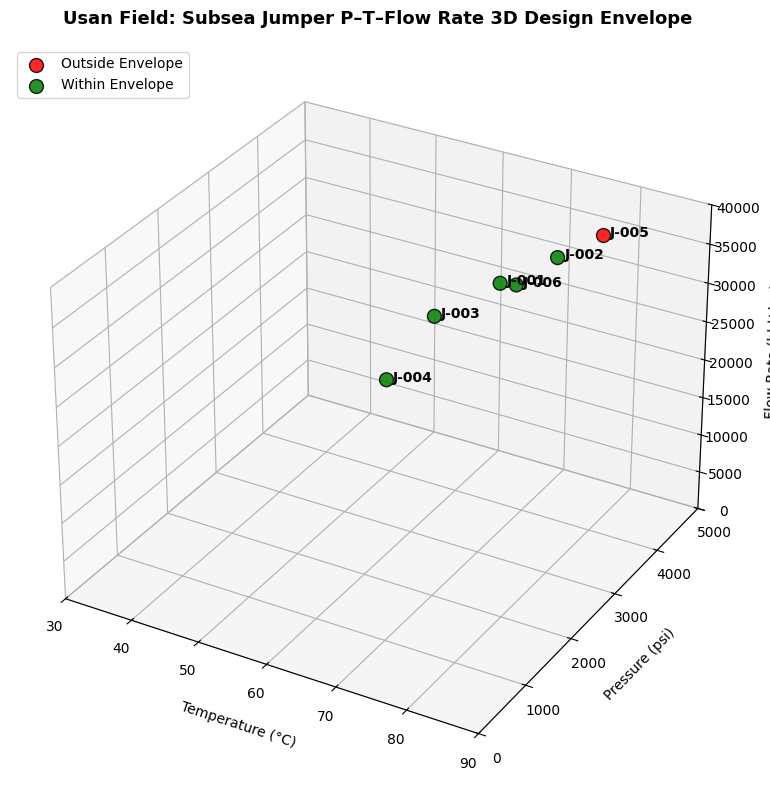

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Define 3-parameter operational limits
limits = {
    'pressure_psi': (500.0, 4467.0),
    'temperature_c': (35.0, 82.0),
    'flow_rate_bpd': (0.0, 35000.0)
}

# 2. Extend Jumper Operating Points (Table 2.9) with Flow Rates (bpd)
jumpers_data = [
    {"jumper_id": "J-001", "pressure_psi": 4200, "temperature_c": 65, "flow_rate_bpd": 28000},
    {"jumper_id": "J-002", "pressure_psi": 4400, "temperature_c": 72, "flow_rate_bpd": 32000},
    {"jumper_id": "J-003", "pressure_psi": 3800, "temperature_c": 58, "flow_rate_bpd": 24000},
    {"jumper_id": "J-004", "pressure_psi": 3200, "temperature_c": 55, "flow_rate_bpd": 18000},
    {"jumper_id": "J-005", "pressure_psi": 4467, "temperature_c": 78, "flow_rate_bpd": 36000},  # Exceeds flow rate limit
    {"jumper_id": "J-006", "pressure_psi": 4100, "temperature_c": 68, "flow_rate_bpd": 29000},
]
jumpers_df = pd.DataFrame(jumpers_data)

# 3. Assess status for each operating point
def evaluate_status(row, limits_dict):
    for param, (min_val, max_val) in limits_dict.items():
        if not (min_val <= row[param] <= max_val):
            return "Outside Envelope"
    return "Within Envelope"

jumpers_df['status'] = jumpers_df.apply(lambda r: evaluate_status(r, limits), axis=1)

# 4. Generate 3D Plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

colors = {'Within Envelope': 'green', 'Outside Envelope': 'red'}

for status, group in jumpers_df.groupby('status'):
    ax.scatter(
        group['temperature_c'],
        group['pressure_psi'],
        group['flow_rate_bpd'],
        c=colors[status],
        s=100,
        label=status,
        edgecolors='black',
        alpha=0.85
    )

# Annotate the jumper IDs
for _, row in jumpers_df.iterrows():
    ax.text(
        row['temperature_c'] + 1.0,
        row['pressure_psi'],
        row['flow_rate_bpd'],
        row['jumper_id'],
        fontsize=10,
        fontweight='bold'
    )

# Formatting
ax.set_title("Usan Field: Subsea Jumper P–T–Flow Rate 3D Design Envelope", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Temperature (°C)", labelpad=10)
ax.set_ylabel("Pressure (psi)", labelpad=10)
ax.set_zlabel("Flow Rate (bbl/day)", labelpad=10)

ax.set_xlim(30, 90)
ax.set_ylim(0, 5000)
ax.set_zlim(0, 40000)

ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

Question 4. Write a function that takes a DataFrame of operating data and returns the percentage of time each parameter was within the design envelope.


In [ ]:
import pandas as pd

def calculate_envelope_compliance(df: pd.DataFrame, limits_dict: dict) -> dict:
    """
    Calculates the percentage of time (or data points) each parameter was within its defined design envelope limits.

    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame containing the operating data.
    limits_dict : dict
        Dictionary where keys are column names in the DataFrame and values are (min, max) limit tuples.

    Returns:
    --------
    dict
        A dictionary containing the compliance percentage (0 to 100) for each parameter.
    """
    compliance_results = {}
    total_records = len(df)

    if total_records == 0:
        raise ValueError("The input DataFrame is empty.")

    for param, (min_val, max_val) in limits_dict.items():
        if param not in df.columns:
            print(f"Warning: Column '{param}' not found in the DataFrame. Skipping.")
            continue

        # Count how many records fall within [min_val, max_val]
        within_limits = df[param].between(min_val, max_val).sum()
        compliance_percentage = (within_limits / total_records) * 100
        compliance_results[param] = round(compliance_percentage, 2)

    return compliance_results

# --- Demo and Verification ---
# Using the limits and dataset defined earlier:
design_limits = {
    'pressure_psi': (500.0, 4467.0),
    'temperature_c': (35.0, 82.0),
    'flow_rate_bpd': (0.0, 35000.0)
}

compliance = calculate_envelope_compliance(jumpers_df, design_limits)
print("Compliance Rate per Parameter (% of points within limits):")
for param, pct in compliance.items():
    print(f" - {param}: {pct}%")

Compliance Rate per Parameter (% of points within limits):
 - pressure_psi: 100.0%
 - temperature_c: 100.0%
 - flow_rate_bpd: 83.33%
